In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, load_npz
import joblib
import warnings
warnings.filterwarnings('ignore')

# ── Configurare device ────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_GPUS = torch.cuda.device_count()

print(f"Device: {device}")
print(f"PyTorch version: {torch.__version__}")
print(f"GPU count: {NUM_GPUS}")

if torch.cuda.is_available():
    for i in range(NUM_GPUS):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

INPUT_PATH = "/kaggle/input/notebooks/catalinagligor22/02-preprocessing/"
OUTPUT_DIR = "/kaggle/working/"

# Imagini + masti
X_train_img = np.load(INPUT_PATH + 'X_train_img.npy')
X_val_img = np.load(INPUT_PATH + 'X_val_img.npy')
X_test_img = np.load(INPUT_PATH + 'X_test_img.npy')
y_train_img = np.load(INPUT_PATH + 'y_train_img.npy')
y_val_img = np.load(INPUT_PATH + 'y_val_img.npy')
y_test_img = np.load(INPUT_PATH + 'y_test_img.npy')

# Date clinice
df_train = pd.read_csv(INPUT_PATH + 'clinical_train.csv')
df_val = pd.read_csv(INPUT_PATH + 'clinical_val.csv')
df_test = pd.read_csv(INPUT_PATH + 'clinical_test.csv')

# Transformatoare
preprocessor = joblib.load(INPUT_PATH + 'preprocessor.pkl')
tfidf = joblib.load(INPUT_PATH + 'tfidf_vectorizer.pkl')

print("Date încărcate cu succes!")
print(f" Imagini train: {X_train_img.shape}")
print(f" Masti train: {y_train_img.shape}")
print(f" Pacienti train: {len(df_train)}")
print(f" Pacienti val: {len(df_val)}")

Device: cuda
PyTorch version: 2.10.0+cu128
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Date încărcate cu succes!
 Imagini train: (3080, 256, 256)
 Masti train: (3080, 256, 256)
 Pacienti train: 47926
 Pacienti val: 10270


In [8]:
# Imagini + masti
X_train_img = np.load(INPUT_PATH + 'X_train_img.npy')
X_val_img   = np.load(INPUT_PATH + 'X_val_img.npy')
X_test_img  = np.load(INPUT_PATH + 'X_test_img.npy')
y_train_img = np.load(INPUT_PATH + 'y_train_img.npy')
y_val_img   = np.load(INPUT_PATH + 'y_val_img.npy')
y_test_img  = np.load(INPUT_PATH + 'y_test_img.npy')

# Date clinice
df_train = pd.read_csv(INPUT_PATH + 'clinical_train.csv')
df_val   = pd.read_csv(INPUT_PATH + 'clinical_val.csv')
df_test  = pd.read_csv(INPUT_PATH + 'clinical_test.csv')

# Transformatoare
preprocessor = joblib.load(INPUT_PATH + 'preprocessor.pkl')
tfidf        = joblib.load(INPUT_PATH + 'tfidf_vectorizer.pkl')

print(" Date încărcate cu succes!")
print(f"   Imagini train:  {X_train_img.shape}")
print(f"   Masti train:    {y_train_img.shape}")
print(f"   Pacienti train: {len(df_train)}")
print(f"   Pacienti val:   {len(df_val)}")

 Date încărcate cu succes!
   Imagini train:  (3080, 256, 256)
   Masti train:    (3080, 256, 256)
   Pacienti train: 47926
   Pacienti val:   10270


In [9]:
class CarotidDataset(Dataset):
    """
    Dataset custom PyTorch pentru imaginile ecografice carotidiene.
    Adaugă dimensiunea canalului cerută de CNN: (N, 256, 256) → (N, 1, 256, 256)
    """
    def __init__(self, images, masks):
        self.images = torch.tensor(images, dtype=torch.float32).unsqueeze(1)
        self.masks = torch.tensor(masks, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]

BATCH_SIZE = 16   # încearcă 24 sau 32 dacă memoria permite

train_dataset = CarotidDataset(X_train_img, y_train_img)
val_dataset = CarotidDataset(X_val_img, y_val_img)
test_dataset = CarotidDataset(X_test_img, y_test_img)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoader creat!")
print(f" Batch size: {BATCH_SIZE}")
print(f" Batch-uri train: {len(train_loader)}")
print(f" Batch-uri val: {len(val_loader)}")

DataLoader creat!
 Batch size: 16
 Batch-uri train: 193
 Batch-uri val: 42


In [10]:
class DoubleConv(nn.Module):
    """Bloc de bază U-Net: Conv → BN → ReLU → Conv → BN → ReLU"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """
    U-Net pentru segmentarea arterei carotide.
    Input: (B, 1, 256, 256)
    Output: (B, 1, 256, 256)
    """
    def __init__(self, features=[64, 128, 256, 512]):
        super().__init__()

        self.encoders = nn.ModuleList()
        self.pools = nn.ModuleList()
        in_ch = 1

        for f in features:
            self.encoders.append(DoubleConv(in_ch, f))
            self.pools.append(nn.MaxPool2d(2))
            in_ch = f

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        self.upconvs = nn.ModuleList()
        self.decoders = nn.ModuleList()

        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f * 2, f, 2, stride=2))
            self.decoders.append(DoubleConv(f * 2, f))

        self.output = nn.Conv2d(features[0], 1, 1)

    def forward(self, x):
        skip_connections = []

        for encoder, pool in zip(self.encoders, self.pools):
            x = encoder(x)
            skip_connections.append(x)
            x = pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for upconv, decoder, skip in zip(self.upconvs, self.decoders, skip_connections):
            x = upconv(x)
            x = torch.cat([skip, x], dim=1)
            x = decoder(x)

        return torch.sigmoid(self.output(x))


model = UNet()

if NUM_GPUS >= 2:
    print("Folosesc U-Net pe 2 GPU-uri cu DataParallel")
    model = nn.DataParallel(model, device_ids=[0, 1])

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"U-Net creat! Parametri antrenabili: {total_params:,}")

Folosesc U-Net pe 2 GPU-uri cu DataParallel
U-Net creat! Parametri antrenabili: 31,036,481


In [11]:
class AttentionBlock(nn.Module):
    def __init__(self, g_ch, x_ch, inter_ch):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(g_ch, inter_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(inter_ch)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(x_ch, inter_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(inter_ch)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(inter_ch, 1, kernel_size=1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi


class AttentionUNet(nn.Module):
    def __init__(self, features=[64, 128, 256, 512]):
        super().__init__()

        self.encoders = nn.ModuleList()
        self.pools = nn.ModuleList()

        in_ch = 1
        for f in features:
            self.encoders.append(DoubleConv(in_ch, f))
            self.pools.append(nn.MaxPool2d(2))
            in_ch = f

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        self.upconvs = nn.ModuleList()
        self.attentions = nn.ModuleList()
        self.decoders = nn.ModuleList()

        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f * 2, f, kernel_size=2, stride=2))
            self.attentions.append(AttentionBlock(g_ch=f, x_ch=f, inter_ch=f // 2))
            self.decoders.append(DoubleConv(f * 2, f))

        self.output = nn.Conv2d(features[0], 1, kernel_size=1)

    def forward(self, x):
        skips = []

        for encoder, pool in zip(self.encoders, self.pools):
            x = encoder(x)
            skips.append(x)
            x = pool(x)

        x = self.bottleneck(x)
        skips = skips[::-1]

        for upconv, attn, decoder, skip in zip(self.upconvs, self.attentions, self.decoders, skips):
            x = upconv(x)
            skip = attn(g=x, x=skip)
            x = torch.cat([skip, x], dim=1)
            x = decoder(x)

        return torch.sigmoid(self.output(x))


att_model = AttentionUNet()

if NUM_GPUS >= 2:
    print("Folosesc Attention U-Net pe 2 GPU-uri cu DataParallel")
    att_model = nn.DataParallel(att_model, device_ids=[0, 1])

att_model = att_model.to(device)

att_params = sum(p.numel() for p in att_model.parameters() if p.requires_grad)
print(f"Attention U-Net creat! Parametri antrenabili: {att_params:,}")

Folosesc Attention U-Net pe 2 GPU-uri cu DataParallel
Attention U-Net creat! Parametri antrenabili: 31,387,053


In [12]:
def dice_loss(pred, target, smooth=1e-6):
    pred_flat = pred.view(-1)
    target_flat = target.view(-1)
    intersection = (pred_flat * target_flat).sum()
    return 1 - (2. * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)

def combined_loss(pred, target):
    bce = nn.BCELoss()(pred, target)
    dice = dice_loss(pred, target)
    return bce + dice

def dice_score(pred, target, threshold=0.5):
    pred_bin = (pred > threshold).float()
    smooth = 1e-6
    intersection = (pred_bin * target).sum()
    return ((2. * intersection + smooth) / (pred_bin.sum() + target.sum() + smooth)).item()

optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

EPOCHS = 30
train_losses, val_losses = [], []
train_dices, val_dices = [], []
best_val_dice = 0.0

print(f"Incep antrenarea U-Net pe {EPOCHS} epoci...\n")

for epoch in range(EPOCHS):
    model.train()
    train_loss, train_dice = 0.0, 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()
        preds = model(imgs)
        loss = combined_loss(preds, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_dice += dice_score(preds.detach().cpu(), masks.detach().cpu())

    model.eval()
    val_loss, val_dice = 0.0, 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            preds = model(imgs)
            val_loss += combined_loss(preds, masks).item()
            val_dice += dice_score(preds.cpu(), masks.cpu())

    tl = train_loss / len(train_loader)
    vl = val_loss / len(val_loader)
    td = train_dice / len(train_loader)
    vd = val_dice / len(val_loader)

    train_losses.append(tl)
    val_losses.append(vl)
    train_dices.append(td)
    val_dices.append(vd)

    scheduler.step(vl)

    if vd > best_val_dice:
        best_val_dice = vd
        torch.save(
            model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict(),
            OUTPUT_DIR + 'unet_best.pth'
        )

    if (epoch + 1) % 5 == 0:
        print(f"Epoca {epoch+1:02d}/{EPOCHS} | "
              f"Loss: {tl:.4f}/{vl:.4f} | "
              f"Dice: {td:.4f}/{vd:.4f} | "
              f"LR: {optimizer.param_groups[0]['lr']:.6f}")

print(f"\n✅ Antrenare U-Net finalizata! Best Val Dice: {best_val_dice:.4f}")

Incep antrenarea U-Net pe 30 epoci...

Epoca 05/30 | Loss: 0.0658/0.0629 | Dice: 0.9484/0.9506 | LR: 0.001000
Epoca 10/30 | Loss: 0.0534/0.0533 | Dice: 0.9569/0.9569 | LR: 0.000500
Epoca 15/30 | Loss: 0.0480/0.0562 | Dice: 0.9611/0.9546 | LR: 0.000500
Epoca 20/30 | Loss: 0.0464/0.0543 | Dice: 0.9623/0.9560 | LR: 0.000500
Epoca 25/30 | Loss: 0.0415/0.0446 | Dice: 0.9663/0.9636 | LR: 0.000250
Epoca 30/30 | Loss: 0.0388/0.0411 | Dice: 0.9684/0.9664 | LR: 0.000250

✅ Antrenare U-Net finalizata! Best Val Dice: 0.9664


In [13]:
optimizer_att = optim.Adam(att_model.parameters(), lr=1e-3)
scheduler_att = optim.lr_scheduler.ReduceLROnPlateau(optimizer_att, patience=3, factor=0.5)

att_train_losses, att_val_losses = [], []
att_train_dices, att_val_dices = [], []
best_att_val_dice = 0.0

print(f"Incep antrenarea Attention U-Net pe {EPOCHS} epoci...\n")

for epoch in range(EPOCHS):
    att_model.train()
    train_loss, train_dice = 0.0, 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer_att.zero_grad()
        preds = att_model(imgs)
        loss = combined_loss(preds, masks)
        loss.backward()
        optimizer_att.step()

        train_loss += loss.item()
        train_dice += dice_score(preds.detach().cpu(), masks.detach().cpu())

    att_model.eval()
    val_loss, val_dice = 0.0, 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            preds = att_model(imgs)
            val_loss += combined_loss(preds, masks).item()
            val_dice += dice_score(preds.cpu(), masks.cpu())

    tl = train_loss / len(train_loader)
    vl = val_loss / len(val_loader)
    td = train_dice / len(train_loader)
    vd = val_dice / len(val_loader)

    att_train_losses.append(tl)
    att_val_losses.append(vl)
    att_train_dices.append(td)
    att_val_dices.append(vd)

    scheduler_att.step(vl)

    if vd > best_att_val_dice:
        best_att_val_dice = vd
        torch.save(
            att_model.module.state_dict() if isinstance(att_model, nn.DataParallel) else att_model.state_dict(),
            OUTPUT_DIR + 'attention_unet_best.pth'
        )

    if (epoch + 1) % 5 == 0:
        print(f"Epoca {epoch+1:02d}/{EPOCHS} | "
              f"Loss: {tl:.4f}/{vl:.4f} | "
              f"Dice: {td:.4f}/{vd:.4f} | "
              f"LR: {optimizer_att.param_groups[0]['lr']:.6f}")

print(f"\n✅ Antrenare Attention U-Net finalizata! Best Val Dice: {best_att_val_dice:.4f}")

Incep antrenarea Attention U-Net pe 30 epoci...

Epoca 05/30 | Loss: 0.0615/0.0680 | Dice: 0.9517/0.9463 | LR: 0.001000
Epoca 10/30 | Loss: 0.0535/0.0646 | Dice: 0.9568/0.9487 | LR: 0.000500
Epoca 15/30 | Loss: 0.0454/0.0456 | Dice: 0.9631/0.9628 | LR: 0.000500
Epoca 20/30 | Loss: 0.0439/0.0451 | Dice: 0.9642/0.9631 | LR: 0.000500
Epoca 25/30 | Loss: 0.0387/0.0433 | Dice: 0.9684/0.9646 | LR: 0.000500
Epoca 30/30 | Loss: 0.0348/0.0400 | Dice: 0.9716/0.9673 | LR: 0.000250

✅ Antrenare Attention U-Net finalizata! Best Val Dice: 0.9673


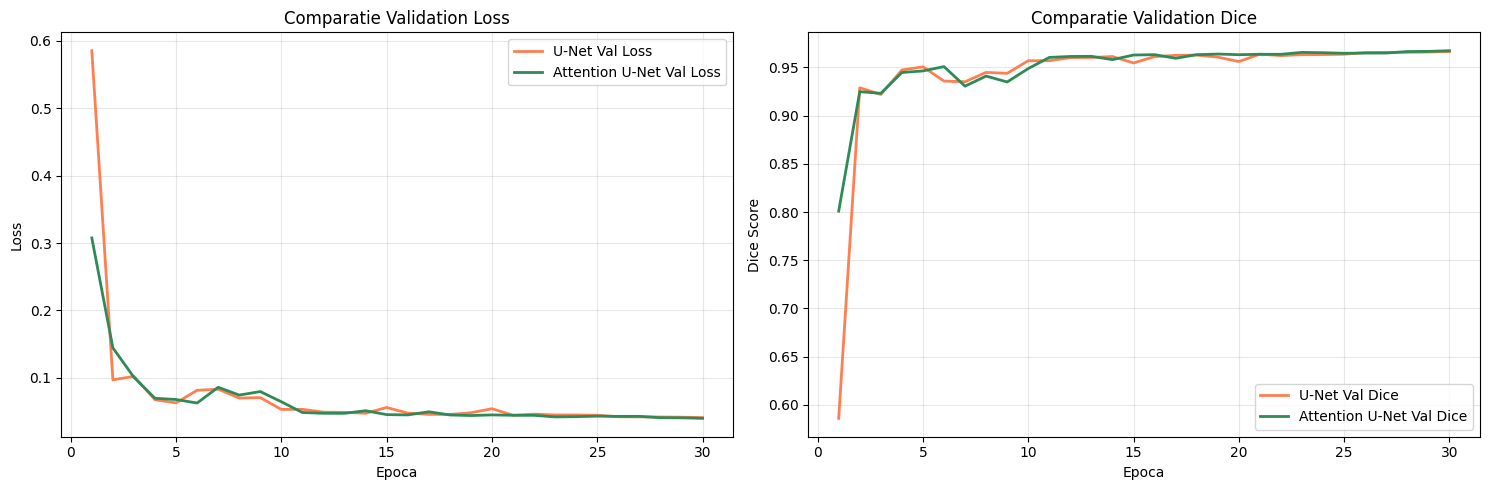

✅ Grafic comparativ salvat!


In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
epochs_range = range(1, EPOCHS + 1)

ax1.plot(epochs_range, val_losses, label='U-Net Val Loss', linewidth=2, color='coral')
ax1.plot(epochs_range, att_val_losses, label='Attention U-Net Val Loss', linewidth=2, color='seagreen')
ax1.set_title('Comparatie Validation Loss')
ax1.set_xlabel('Epoca')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs_range, val_dices, label='U-Net Val Dice', linewidth=2, color='coral')
ax2.plot(epochs_range, att_val_dices, label='Attention U-Net Val Dice', linewidth=2, color='seagreen')
ax2.set_title('Comparatie Validation Dice')
ax2.set_xlabel('Epoca')
ax2.set_ylabel('Dice Score')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'unet_vs_attention_unet.png', dpi=150)
plt.show()

print("✅ Grafic comparativ salvat!")

In [15]:
seg_results = pd.DataFrame({
    "Model": ["U-Net", "Attention U-Net"],
    "Best Val Dice": [best_val_dice, best_att_val_dice],
    "Last Train Loss": [train_losses[-1], att_train_losses[-1]],
    "Last Val Loss": [val_losses[-1], att_val_losses[-1]],
    "Params": [total_params, att_params]
})

print("=" * 75)
print("COMPARATIE MODELE DE SEGMENTARE")
print("=" * 75)
print(seg_results.to_string(index=False))
print("=" * 75)

best_model_name = seg_results.sort_values("Best Val Dice", ascending=False).iloc[0]["Model"]
print(f"\nModel ales pentru segmentare: {best_model_name}")

seg_results.to_csv(OUTPUT_DIR + "segmentation_model_comparison.csv", index=False)

COMPARATIE MODELE DE SEGMENTARE
          Model  Best Val Dice  Last Train Loss  Last Val Loss   Params
          U-Net       0.966400         0.038777       0.041145 31036481
Attention U-Net       0.967272         0.034791       0.040028 31387053

Model ales pentru segmentare: Attention U-Net


In [16]:
# Pregătire features clinice
numeric_features   = ['age_years', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure']
categoric_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

X_train_tab = preprocessor.transform(df_train[numeric_features + categoric_features])
X_val_tab   = preprocessor.transform(df_val[numeric_features + categoric_features])

X_train_tfidf = tfidf.transform(df_train['risk_text'])
X_val_tfidf   = tfidf.transform(df_val['risk_text'])

X_train_clin = hstack([X_train_tab, X_train_tfidf])
X_val_clin   = hstack([X_val_tab,   X_val_tfidf])

y_train_clin = df_train['cardio'].values
y_val_clin   = df_val['cardio'].values

# ── Model 1: XGBoost ──────────────────────────────────────
print("Antrenez XGBoost...")
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    device='cpu'
)
xgb.fit(X_train_clin, y_train_clin,
        eval_set=[(X_val_clin, y_val_clin)],
        verbose=50)

xgb_acc = accuracy_score(y_val_clin, xgb.predict(X_val_clin))
xgb_f1  = f1_score(y_val_clin,       xgb.predict(X_val_clin))
xgb_auc = roc_auc_score(y_val_clin,  xgb.predict_proba(X_val_clin)[:,1])
print(f"\n XGBoost — Acc: {xgb_acc:.4f} | F1: {xgb_f1:.4f} | AUC: {xgb_auc:.4f}")

# ── Model 2: Logistic Regression (baseline) ──────────────
print("\nAntrenez Logistic Regression (baseline)...")
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_clin, y_train_clin)

lr_acc = accuracy_score(y_val_clin, lr.predict(X_val_clin))
lr_f1  = f1_score(y_val_clin,       lr.predict(X_val_clin))
lr_auc = roc_auc_score(y_val_clin,  lr.predict_proba(X_val_clin)[:,1])
print(f" Logistic Regression — Acc: {lr_acc:.4f} | F1: {lr_f1:.4f} | AUC: {lr_auc:.4f}")

Antrenez XGBoost...
[0]	validation_0-logloss:0.67993
[50]	validation_0-logloss:0.54377
[100]	validation_0-logloss:0.54098
[150]	validation_0-logloss:0.54130
[200]	validation_0-logloss:0.54148
[250]	validation_0-logloss:0.54174
[299]	validation_0-logloss:0.54232

 XGBoost — Acc: 0.7334 | F1: 0.7183 | AUC: 0.8014

Antrenez Logistic Regression (baseline)...
 Logistic Regression — Acc: 0.7310 | F1: 0.7122 | AUC: 0.7935


In [17]:
results = pd.DataFrame({
    'Model':    ['XGBoost', 'Logistic Regression'],
    'Accuracy': [xgb_acc,  lr_acc],
    'F1-Score': [xgb_f1,   lr_f1],
    'AUC-ROC':  [xgb_auc,  lr_auc]
})

print("=" * 55)
print("TABEL COMPARATIV MODELE CLINICE")
print("=" * 55)
print(results.to_string(index=False))
print("=" * 55)
print(f"\nModel ales: XGBoost (AUC mai mare: {xgb_auc:.4f})")

TABEL COMPARATIV MODELE CLINICE
              Model  Accuracy  F1-Score  AUC-ROC
            XGBoost  0.733398  0.718313 0.801392
Logistic Regression  0.730964  0.712158 0.793468

Model ales: XGBoost (AUC mai mare: 0.8014)


In [18]:
#Salvare modele

torch.save(
    model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict(),
    OUTPUT_DIR + 'unet_final.pth'
)

torch.save(
    att_model.module.state_dict() if isinstance(att_model, nn.DataParallel) else att_model.state_dict(),
    OUTPUT_DIR + 'attention_unet_final.pth'
)

joblib.dump(xgb, OUTPUT_DIR + 'xgboost_model.pkl')
joblib.dump(lr, OUTPUT_DIR + 'logistic_regression.pkl')

results.to_csv(OUTPUT_DIR + 'model_comparison.csv', index=False)

print("Modele salvate in Output:")
print(" unet_best.pth ← cel mai bun U-Net")
print(" unet_final.pth ← U-Net final")
print(" attention_unet_best.pth ← cel mai bun Attention U-Net")
print(" attention_unet_final.pth ← Attention U-Net final")
print(" segmentation_model_comparison.csv ← comparatie segmentare")
print(" unet_training_curves.png ← grafice U-Net")
print(" unet_vs_attention_unet.png ← comparatie curbe")
print(" xgboost_model.pkl ← XGBoost antrenat")
print(" logistic_regression.pkl ← Baseline LR")
print(" model_comparison.csv ← tabel comparativ clinic")

Modele salvate in Output:
 unet_best.pth ← cel mai bun U-Net
 unet_final.pth ← U-Net final
 attention_unet_best.pth ← cel mai bun Attention U-Net
 attention_unet_final.pth ← Attention U-Net final
 segmentation_model_comparison.csv ← comparatie segmentare
 unet_training_curves.png ← grafice U-Net
 unet_vs_attention_unet.png ← comparatie curbe
 xgboost_model.pkl ← XGBoost antrenat
 logistic_regression.pkl ← Baseline LR
 model_comparison.csv ← tabel comparativ clinic
